<a href="https://colab.research.google.com/github/matbarrett/LinAlgProject/blob/main/notebooks/02_svd_approximation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint 2

The SVD lets us rebuild an image using fewer terms. We try several ranks to see how much detail is left.

In [1]:
from pathlib import Path
import subprocess
import sys

# Use this checkout locally, or download the project when running in Colab.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "bird_image.jpg").exists() and (p / "src").is_dir()), None)
if ROOT is None:
    ROOT = Path.cwd() / "LinAlgProject"
    if (ROOT / ".git").exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "https://github.com/matbarrett/LinAlgProject.git",
                        str(ROOT)], check=True)
sys.path.insert(0, str(ROOT / "src"))
print("Project:", ROOT.name)

Project: LinAlgProject


This loads the project photo and the functions in `src/compress.py`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = data.camera().astype(float)
print(A.shape, A.dtype)

(512, 512) float64


The camera matrix is converted to float before doing linear algebra. This prevents the wraparound seen in Milestone 1.

In [3]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print('U:', U.shape, 's:', s.shape, 'Vt:', Vt.shape)
A_back = U @ np.diag(s) @ Vt
print('Rebuilt correctly?', np.allclose(A, A_back))
print('Largest error:', np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 2.2396307031158358e-11


Multiplying `U`, the diagonal matrix of singular values, and `Vt` gives the original image back. The largest difference is about 2.24e-11, which is just rounding error.

First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


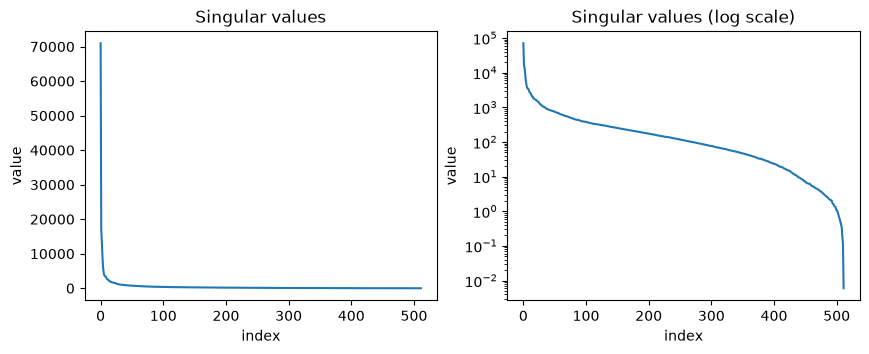

In [4]:
print('First five:', np.round(s[:5], 1))
print('50th, 200th, last:', round(s[49], 1),
round(s[199], 1), round(s[-1], 3))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(s)
ax1.set(title='Singular values', xlabel='index', ylabel='value')
ax2.semilogy(s)
ax2.set(title='Singular values (log scale)', xlabel='index', ylabel='value')
plt.show()

The first singular value is much larger than the others. The values drop quickly at first, then more slowly. The log plot makes the small values easier to compare.

In [5]:
def rank_k_approx(A, k):
  # Return the rank-k SVD approximation of A.
  U, s, Vt = np.linalg.svd(A, full_matrices=False)
  return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

This keeps the first k columns of U, k singular values, and k rows of Vt, then multiplies them to rebuild the approximation. A reusable version is also saved in `src/compress.py` for Milestone 3.

In [6]:
print('rank of A_10:', np.linalg.matrix_rank(rank_k_approx(A, 10)))
print('k = 512 gives A back?', np.allclose(rank_k_approx(A, 512), A))
stripes = np.outer([1, 0, 1, 0], [1, 1, 1, 1]).astype(float)
print('singular values of stripes:',
  np.round(np.linalg.svd(stripes, compute_uv=False), 4))

rank of A_10: 10


k = 512 gives A back? True
singular values of stripes: [2.8284 0.     0.     0.    ]


The rank check gives 10, and using all 512 terms rebuilds the camera image. The stripe matrix has only one nonzero singular value, which matches its rank of 1.

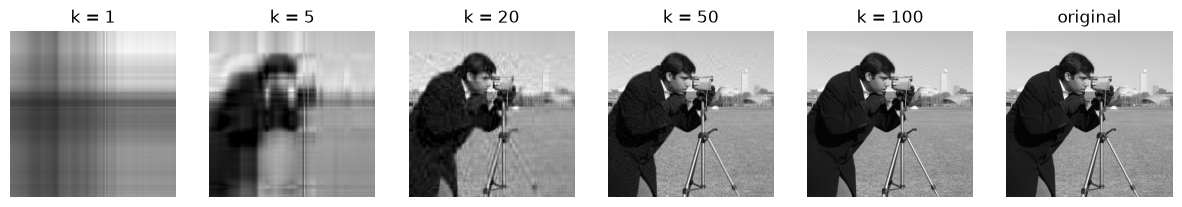

In [7]:
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
  Ak = np.clip(rank_k_approx(A, k), 0, 255)
  ax.imshow(Ak, cmap='gray', vmin=0, vmax=255)
  ax.set_title(f'k = {k}')
  ax.axis('off')
axes[-1].imshow(A, cmap='gray', vmin=0, vmax=255)
axes[-1].set_title('original')
axes[-1].axis('off')
plt.show()

More terms bring back more detail. We clip only for display, and use the same brightness range for every image so the comparison is fair.

## Exercises

### 1. Singular values of a small matrix
For M = [[3, 0], [4, 5]], M^T M = [[25, 20], [20, 25]]. Its characteristic equation is `(25 - lambda)^2 - 400 = 0`, giving eigenvalues 45 and 5. The singular values are their square roots: `3*sqrt(5)` and `sqrt(5)`.

In [8]:
M = np.array([[3., 0.], [4., 5.]])
print("M.T @ M:\n", M.T @ M)
print("Eigenvalues:", np.linalg.eigvalsh(M.T @ M))
print("From eigenvalues:", np.sqrt(np.linalg.eigvalsh(M.T @ M)[::-1]))
print("From SVD:", np.linalg.svd(M, compute_uv=False))

M.T @ M:
 [[25. 20.]
 [20. 25.]]
Eigenvalues: [ 5. 45.]
From eigenvalues: [6.70820393 2.23606798]
From SVD: [6.70820393 2.23606798]


The two methods agree. Changing the signs of both vectors does not change the outer product: `(-u1)(-v1)^T = u1 v1^T`. The two minus signs cancel.

### 2. Error from the discarded singular values

In [9]:
actual = np.linalg.norm(A - rank_k_approx(A, 20))
predicted = np.sqrt(np.sum(s[20:]**2))
print("Measured error:", actual)
print("Predicted error:", predicted)
print("Agree?", np.isclose(actual, predicted))

Measured error: 7699.909141968125
Predicted error: 7699.909141968125
Agree? True


Both errors are about 7699.91. Eckart-Young gives the error from the discarded singular values. Since Python starts counting at 0, keeping 20 terms means keeping `s[0]` through `s[19]`. The discarded terms start at `s[20]`.

### 3. Compression of the project photo

Shape: (678, 452)
Data type: uint8


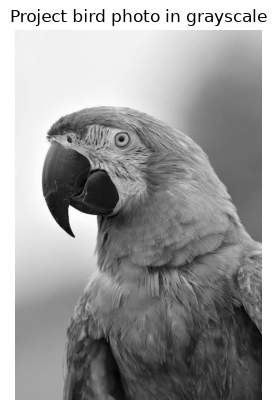

In [10]:
from PIL import Image

img = Image.open(ROOT / "bird_image.jpg").convert("L")
img.thumbnail((800, 800))
P = np.array(img)
print("Shape:", P.shape)
print("Data type:", P.dtype)
plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("Project bird photo in grayscale")
plt.axis("off")
plt.show()

This is the same bird photo from Milestone 1. The next cell converts its pixel values to float before computing the SVD.

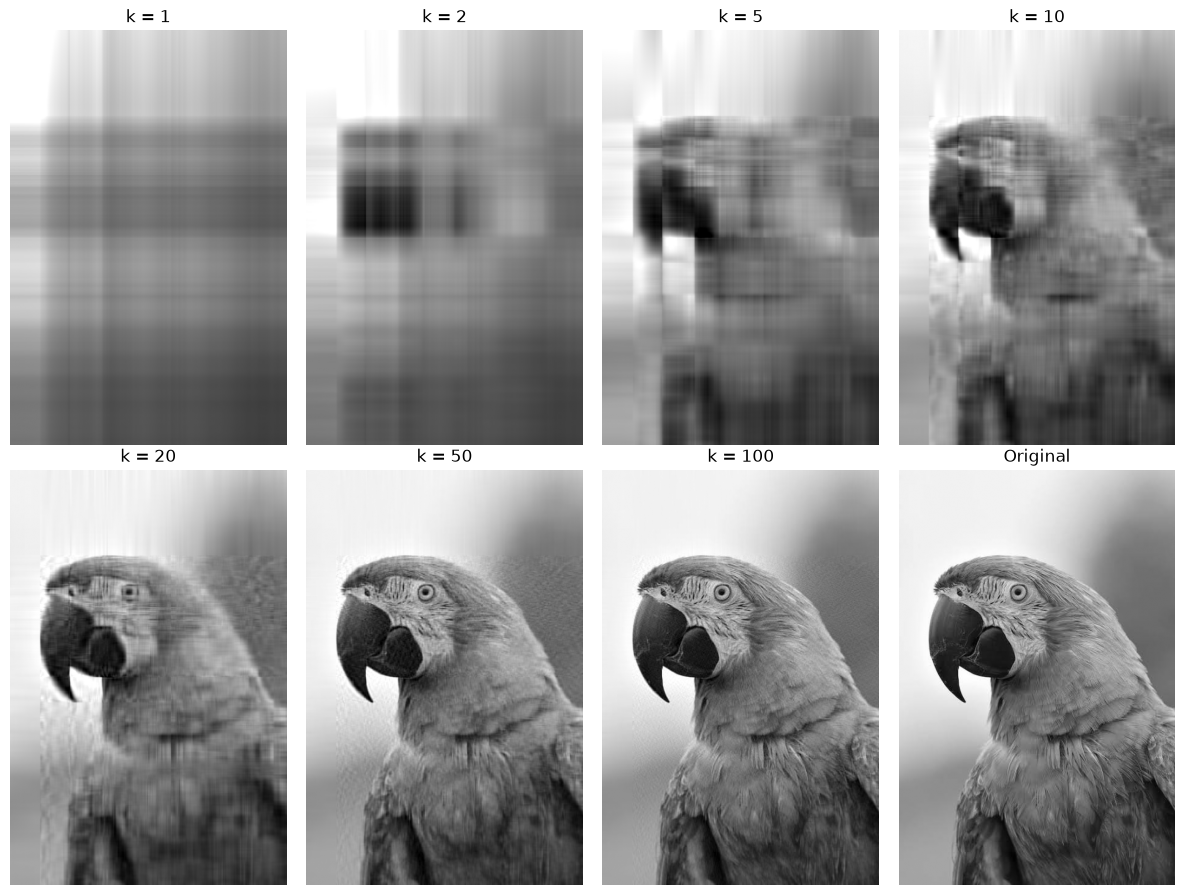

In [11]:
P_float = P.astype(float)
photo_ranks = [1, 2, 5, 10, 20, 50, 100]
fig, axes = plt.subplots(2, 4, figsize=(12, 9))
for ax, k in zip(axes.flat, photo_ranks):
    ax.imshow(np.clip(rank_k_approx(P_float, k), 0, 255), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}")
    ax.axis("off")
axes.flat[-1].imshow(P_float, cmap="gray", vmin=0, vmax=255)
axes.flat[-1].set_title("Original")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig(ROOT / "figures" / "bird_rank_comparison.png", dpi=150)
plt.show()

Of the ranks shown, k = 5 is the first where the head and curved beak look recognizable. It is still blurry. At k = 10 the outline is clearer, and at k = 20 the eye starts to show. The exact cutoff depends on what we count as recognizable. The bird takes up most of the photo and has a fairly plain background, so it can look recognizable at a different rank than the camera image.